# Plot marginals

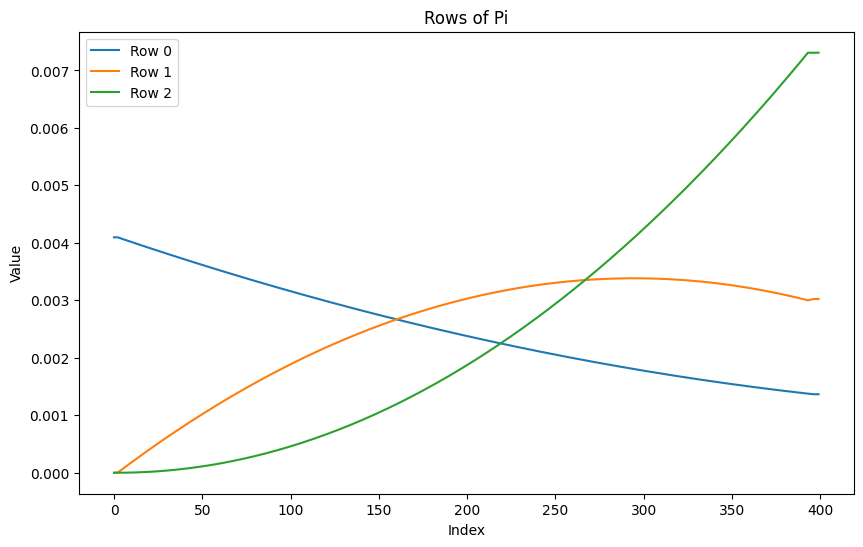

In [38]:
import WERM.marginals

# Plot the rows of pi
n = 400
Δ = lambda n: int(n/100) 
L = 3
pi = WERM.marginals.compute_pi(L, n, Δ(n), L_is_upper_bound=True)
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for i in range(len(pi)):
    plt.plot(pi[i], label=f'Row {i}')
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Rows of Pi')
plt.legend()
plt.show()

In [1]:
import numpy as np
np.logspace(-1, 3, 5)
np.logspace(-1, 4.5, 5)

array([1.00000000e-01, 2.37137371e+00, 5.62341325e+01, 1.33352143e+03,
       3.16227766e+04])

# Compare simple vs. extended WERM

In [ ]:
from WERM.signal_priors import GaussianSignal
import WERM.model
import WERM.general_fixed_point_eqns as fp
import WERM.performance_measures
import WERM.estimators
from WERM.config import η_to_ψ
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from functools import partial
from tqdm.auto import tqdm  # Import tqdm for progress bars
import time
tqdm = partial(tqdm, position=0, leave=True)


# 1. Simulation Parameters
p = 500
L = 3 # num signals (L-1 changepoints)
noise_std = 0.01
δ_list = [2.0, 3.0, 4.0, 5.0]  # List of δ values
num_trials = 1
fractional_chgpt_locations = np.array([0.6])

# Loss Function (Least Squares)
M = lambda u, v: jnp.power(u - v, 2)

# 2. Results Storage for Comparison
results = {
    'haus_simple': np.zeros((len(δ_list), num_trials)),
    'size_simple': np.zeros((len(δ_list), num_trials)),
    'runtime_simple': np.zeros((len(δ_list), num_trials)),
    'haus_ext': np.zeros((len(δ_list), num_trials)),
    'size_ext': np.zeros((len(δ_list), num_trials)),
    'runtime_ext': np.zeros((len(δ_list), num_trials)),
    'haus_elbow': np.zeros((len(δ_list), num_trials)),
    'size_elbow': np.zeros((len(δ_list), num_trials)),
    'runtime_elbow': np.zeros((len(δ_list), num_trials)),
}

# 3. Main Loop
for i, δ in enumerate(tqdm(δ_list, desc="Iterating over δ")):
    n = int(δ * p)
    Delta = lambda n: int(n / 10)  # Window size for changepoint detection
    true_chgpt_locations_fn = lambda n_len: (n_len * fractional_chgpt_locations).astype(int)

    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # Signal Prior Setup
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L)
    # Add some correlation to the covariance matrix
    # for j_ in range(L):
    #     for k_ in range(j_ + 1, L):
    #         B̃_cov[j_, k_] = B̃_cov[k_, j_] = κ**2 * δ * 0.00 * (j_ + k_) / L  # Example correlation
    signal_prior = GaussianSignal(B̃_cov)

    gamma_candidates = np.logspace(1, 10, 4)  # Candidates for gamma in ERM
    
    for j in tqdm(range(num_trials), desc=f"Trials for δ={δ}", leave=False):
        # --- Data Generation ---
        B̃ = signal_prior.sample(p)
        X = nprandom.normal(0, np.sqrt(1/n), (n, p))
        ε = nprandom.normal(0, 1, size=(n, )) * noise_std # noise vector
        
        true_chgpts = true_chgpt_locations_fn(n)
        # C_true = WERM.config.η_to_ψ(true_chgpts, n)
        Θ = X @ B̃
        y = jax.vmap(WERM.model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        
        # --- Run and Time Simple Weighted ERM ---
        start_time_simple = time.time()
        gamma_hat_1 = WERM.estimators.weighted_ermCV(X, y, M, L, Delta(n), gamma_candidates=gamma_candidates, L_is_upper_bound = True, brute_force=False)
        # gamma_hat_1 = 10
        opt_chgpt_loc_erm_simple = WERM.estimators.weighted_erm(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_1,
            return_B_hat=False, brute_force = False
        )
        results['runtime_simple'][i, j] = time.time() - start_time_simple
        
        # --- Run and Time Weighted ERM Extended Penalized ---
        start_time_ext = time.time()
        gamma_hat_2 = WERM.estimators.weighted_erm_extended_penalizedCV(X, y, M, L, Delta(n), gamma_candidates=gamma_candidates, brute_force=False)
        # gamma_hat_2 = 10
        opt_chgpt_loc_erm_extended = WERM.estimators.weighted_erm_extended_penalized(
            X=X, y=y, M=M, L=L, Delta_n=Delta(n), gamma=gamma_hat_2,
            brute_force=False, min_window_size=300
        )
        results['runtime_ext'][i, j] = time.time() - start_time_ext

        # --- Run and Time Weighted ERM Extended Elbow ---
        start_time_elbow = time.time()
        opt_chgpt_loc_erm_extended_elbow = WERM.estimators.weighted_erm_extended_elbow(
            X=X, y=y, M=M, Delta_n=Delta(n), brute_force=False
        )
        results['runtime_elbow'][i, j] = time.time() - start_time_elbow
        
        # --- Store Results for All Three Methods ---
        # Simple Method
        results['haus_simple'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_simple, true_chgpts)
        results['size_simple'][i, j] = len(opt_chgpt_loc_erm_simple[opt_chgpt_loc_erm_simple != -1])
        # Extended Penalized Method
        results['haus_ext'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_extended, true_chgpts)
        results['size_ext'][i, j] = len(opt_chgpt_loc_erm_extended[opt_chgpt_loc_erm_extended != -1])
        # Extended Elbow Method
        results['haus_elbow'][i, j] = (1/n) * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm_extended_elbow, true_chgpts)
        results['size_elbow'][i, j] = len(opt_chgpt_loc_erm_extended_elbow[opt_chgpt_loc_erm_extended_elbow != -1])


# 4. Plotting Results
PAL = ['#0c2c84', '#e66101', '#1d91c0', '#fdb863', '#7fcdbb', '#c7e9b4']
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Weighted ERM Performance Analysis: Simple vs. Extended vs. Elbow', fontsize=16)

# Hausdorff Distance Plot
ax = axs[0]
ax.errorbar(δ_list, np.mean(results['haus_simple'], axis=1), 
            yerr=np.std(results['haus_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['haus_ext'], axis=1), 
            yerr=np.std(results['haus_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['haus_elbow'], axis=1), 
            yerr=np.std(results['haus_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim((0, 0.3))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Hausdorff Distance / n")
ax.set_title("Changepoint Location Error")
ax.legend()
ax.grid(True, linestyle=':')

# Changepoint Set Size Plot
ax = axs[1]
ax.errorbar(δ_list, np.mean(results['size_simple'], axis=1), 
            yerr=np.std(results['size_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['size_ext'], axis=1), 
            yerr=np.std(results['size_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['size_elbow'], axis=1), 
            yerr=np.std(results['size_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.axhline(y=len(fractional_chgpt_locations), color='black', linestyle=':', label=f'True Size ({len(fractional_chgpt_locations)})')
ax.set_ylim((0, L + 2))
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Number of Changepoints Found")
ax.set_title("Changepoint Set Size")
ax.legend()
ax.grid(True, linestyle=':')

# Runtime Plot
ax = axs[2]
ax.errorbar(δ_list, np.mean(results['runtime_simple'], axis=1), 
            yerr=np.std(results['runtime_simple'], axis=1), 
            label="Simple", marker="o", ls="-.", c=PAL[0])
ax.errorbar(δ_list, np.mean(results['runtime_ext'], axis=1), 
            yerr=np.std(results['runtime_ext'], axis=1), 
            label="Extended Penalized", marker="s", ls="--", c=PAL[1])
ax.errorbar(δ_list, np.mean(results['runtime_elbow'], axis=1), 
            yerr=np.std(results['runtime_elbow'], axis=1), 
            label="Extended Elbow", marker="d", ls=":", c=PAL[2])
ax.set_ylim(bottom=0)
ax.set_xlabel("δ = n/p")
ax.set_ylabel("Runtime (seconds)")
ax.set_title("Method Runtime")
ax.legend()
ax.grid(True, linestyle=':')

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

Iterating over δ:   0%|          | 0/4 [00:00<?, ?it/s]

Trials for δ=2.0:   0%|          | 0/1 [00:00<?, ?it/s]

Running 2-fold CV for 4 gamma candidates...


CV Progress:   0%|          | 0/4 [00:00<?, ?it/s]

Finding change points:   0%|          | 0/2 [00:00<?, ?it/s]

Finding change points:   0%|          | 0/2 [00:00<?, ?it/s]

... (101 outputs left out)

Finding change points:   0%|          | 0/2 [00:00<?, ?it/s]

Finding change points:   0%|          | 0/2 [00:00<?, ?it/s]

mean_scores: [np.float64(5.76269355189256e-07), np.float64(5.76269355189256e-07), np.float64(5.76269355189256e-07), np.float64(5.76269355189256e-07)]
CV finished. Best gamma found: 10.0000 (score: 0.0000)


Finding change points:   0%|          | 0/2 [00:00<?, ?it/s]

# Oldish

  0%|          | 0/6 [00:00<?, ?it/s]

δ =  1.8
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.23180485491940359
        x: [-2.070e-01 -1.115e+00 ... -3.367e-01 -9.643e-01]
      nit: 24
      jac: [-2.695e-06  1.987e-06 ...  5.273e-06  4.843e-06]
     nfev: 26
     njev: 26
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.2784184931300642
        x: [-2.722e-02 -8.545e-01 ... -6.846e-01 -5.083e+00]
      nit: 27
      jac: [ 1.857e-06  1.038e-06 ...  5.653e-06 -1.344e-06]
     nfev: 30
     njev: 30
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [609]
Done optimizing gof erm.


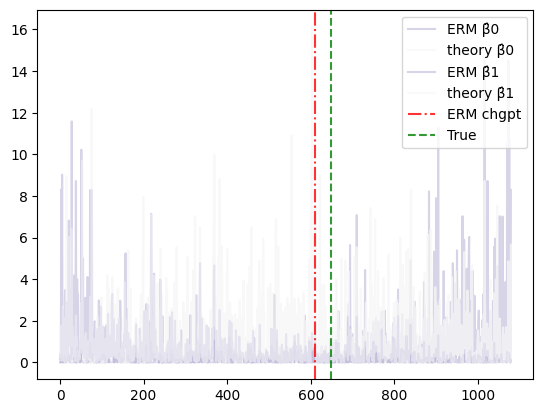

 50%|█████     | 1/2 [00:00<00:00,  1.38it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.2537017252610613
        x: [ 1.204e+00 -9.330e-01 ...  6.799e-01  1.010e+00]
      nit: 26
      jac: [ 2.061e-06 -4.113e-07 ...  5.400e-07  4.880e-08]
     nfev: 30
     njev: 30
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.303859205277477
        x: [ 2.001e+00 -7.042e-01 ...  2.314e+00 -1.456e+00]
      nit: 26
      jac: [ 2.253e-07 -9.150e-08 ...  3.442e-06 -1.541e-06]
     nfev: 29
     njev: 29
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [641]
Done optimizing gof erm.


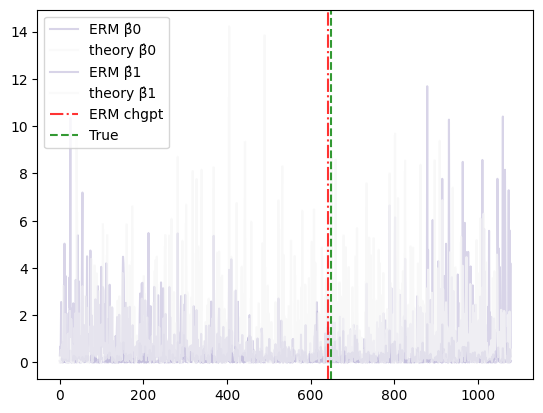

 17%|█▋        | 1/6 [00:01<00:05,  1.05s/it]

δ =  2.0
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.2804272565712793
        x: [-2.063e+00  9.264e-01 ...  5.257e-01 -2.873e-01]
      nit: 22
      jac: [-7.151e-07  3.192e-06 ...  3.580e-06 -1.378e-06]
     nfev: 26
     njev: 26
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.3284824826649116
        x: [-1.756e+00  1.375e+00 ... -2.995e-01  1.307e+00]
      nit: 22
      jac: [-1.221e-06  1.104e-06 ...  4.642e-06 -4.067e-07]
     nfev: 26
     njev: 26
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [721]
Done optimizing gof erm.


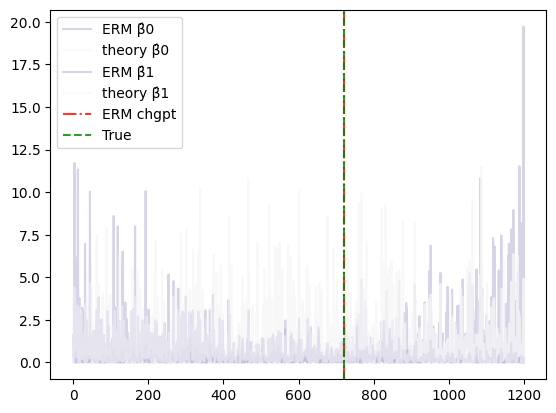

 50%|█████     | 1/2 [00:00<00:00,  1.55it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.258215930837198
        x: [-1.912e+00  6.237e-01 ...  1.795e+00  2.809e-01]
      nit: 23
      jac: [ 2.737e-06  3.173e-06 ... -5.966e-07 -1.186e-06]
     nfev: 27
     njev: 27
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.32617258274888306
        x: [-1.904e+00 -2.734e-02 ...  1.932e+00  1.131e+00]
      nit: 22
      jac: [-2.268e-06  2.567e-06 ...  9.305e-07 -3.705e-06]
     nfev: 25
     njev: 25
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [700]
Done optimizing gof erm.


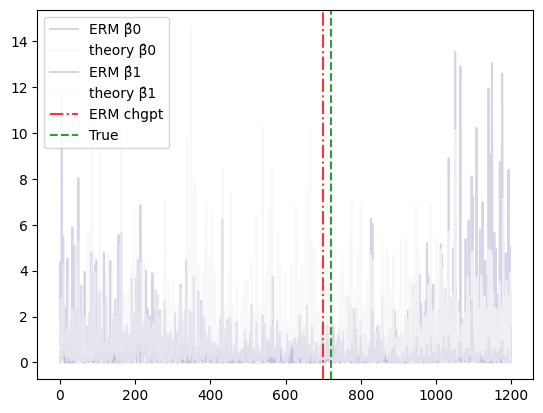

 33%|███▎      | 2/6 [00:02<00:04,  1.01s/it]

δ =  2.5
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.3719742979276843
        x: [ 3.033e-01  2.454e+00 ...  3.417e-01  3.068e-01]
      nit: 17
      jac: [-1.556e-07  8.829e-08 ... -6.834e-07  9.780e-07]
     nfev: 20
     njev: 20
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.4261907489608153
        x: [-4.706e-01  2.795e+00 ... -7.495e-02  6.715e-01]
      nit: 18
      jac: [-1.059e-06  1.338e-06 ... -1.439e-06  4.486e-07]
     nfev: 21
     njev: 21
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [886]
Done optimizing gof erm.


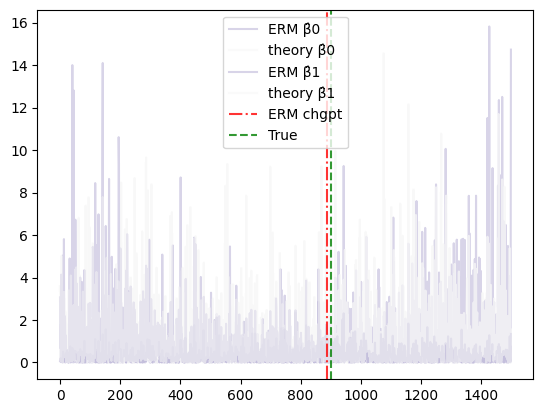

 50%|█████     | 1/2 [00:00<00:00,  1.82it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.3600472525718089
        x: [-8.592e-01  1.608e-01 ...  2.373e+00  7.971e-01]
      nit: 17
      jac: [ 2.797e-06  9.771e-07 ... -1.243e-06 -3.313e-06]
     nfev: 21
     njev: 21
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.4633086747794134
        x: [ 6.484e-01  3.184e-01 ...  3.961e+00  6.617e-01]
      nit: 18
      jac: [ 1.485e-06  5.023e-06 ... -2.732e-06  3.075e-06]
     nfev: 21
     njev: 21
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [893]
Done optimizing gof erm.


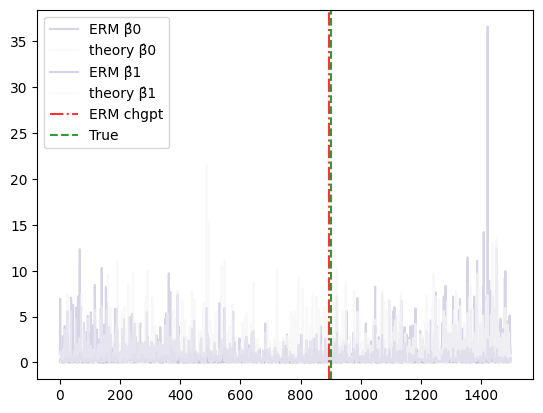

 50%|█████     | 3/6 [00:02<00:02,  1.09it/s]

δ =  3.0
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.38474096230478033
        x: [ 1.456e+00 -3.703e+00 ... -1.288e+00 -6.109e-01]
      nit: 15
      jac: [ 1.113e-06  5.111e-07 ...  1.558e-06  6.231e-07]
     nfev: 18
     njev: 18
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.486178918159622
        x: [ 1.331e+00 -2.392e+00 ... -2.354e-01  7.803e-01]
      nit: 14
      jac: [-1.540e-06 -1.457e-06 ...  1.216e-06  1.153e-06]
     nfev: 17
     njev: 17
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1080]
Done optimizing gof erm.


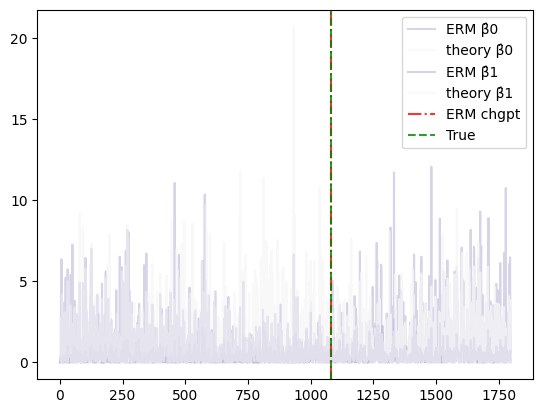

 50%|█████     | 1/2 [00:00<00:00,  1.88it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.37014108963640424
        x: [ 1.486e+00 -1.421e+00 ... -3.038e-01 -3.011e+00]
      nit: 15
      jac: [ 7.544e-08 -2.125e-06 ... -9.130e-07  5.292e-07]
     nfev: 17
     njev: 17
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.4840072474983127
        x: [ 5.829e-01 -2.086e+00 ... -5.852e-01  6.921e-01]
      nit: 15
      jac: [ 1.332e-06 -1.212e-06 ...  3.742e-06  8.923e-07]
     nfev: 18
     njev: 18
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1080]
Done optimizing gof erm.


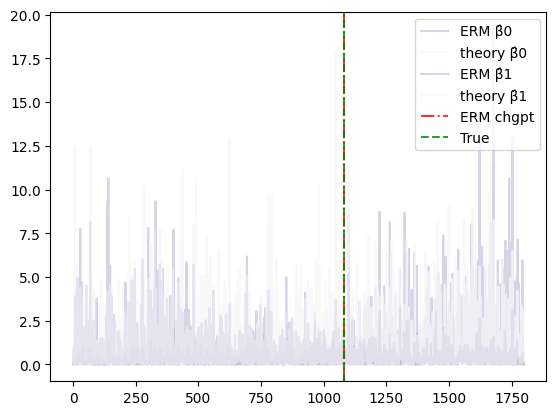

 67%|██████▋   | 4/6 [00:03<00:01,  1.13it/s]

δ =  4.0
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.41492857631317365
        x: [-2.979e+00  1.914e+00 ...  2.899e+00 -2.238e+00]
      nit: 11
      jac: [ 7.660e-07  1.246e-07 ...  7.380e-07 -1.074e-06]
     nfev: 13
     njev: 13
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.5120141761529161
        x: [-1.289e+00 -7.737e-01 ...  2.518e+00  3.951e-01]
      nit: 11
      jac: [ 7.889e-07 -4.045e-06 ...  1.128e-06 -1.251e-06]
     nfev: 13
     njev: 13
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1440]
Done optimizing gof erm.


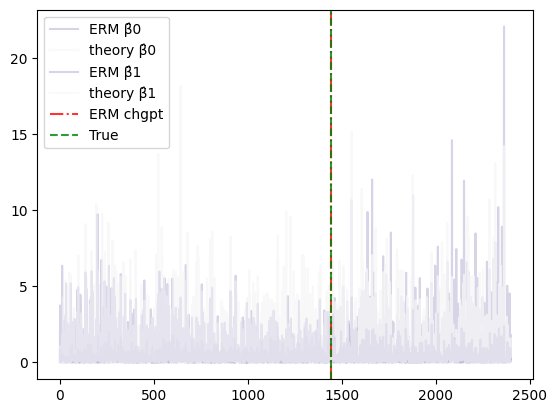

 50%|█████     | 1/2 [00:00<00:00,  1.79it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.4220801356786977
        x: [-1.681e+00  1.090e+00 ...  2.134e+00 -4.006e+00]
      nit: 11
      jac: [ 1.550e-07 -8.076e-07 ...  1.165e-06 -1.980e-06]
     nfev: 13
     njev: 13
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.5048871527165574
        x: [-1.967e+00 -5.171e-01 ...  1.374e+00 -2.171e+00]
      nit: 10
      jac: [-6.223e-06 -1.300e-06 ...  3.203e-10  1.365e-06]
     nfev: 12
     njev: 12
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1440]
Done optimizing gof erm.


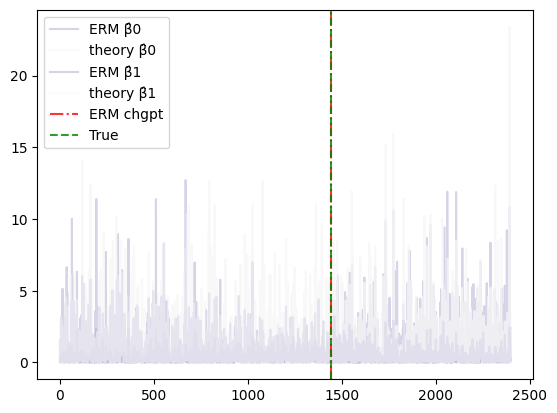

 83%|████████▎ | 5/6 [00:04<00:00,  1.14it/s]

δ =  5.0
Computing marginals of prior...


  0%|          | 0/2 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.48056772473885173
        x: [-3.370e+00  2.714e-01 ... -6.456e-01 -2.809e+00]
      nit: 10
      jac: [-1.361e-07 -1.111e-06 ...  2.912e-07  1.801e-07]
     nfev: 12
     njev: 12
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.6065938309811875
        x: [-8.395e-01 -7.394e-01 ...  1.280e+00 -2.178e+00]
      nit: 10
      jac: [ 3.703e-07 -1.554e-06 ... -2.795e-06  3.877e-06]
     nfev: 12
     njev: 12
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1800]
Done optimizing gof erm.


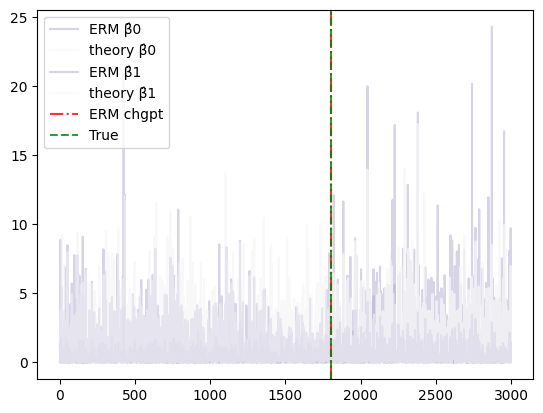

 50%|█████     | 1/2 [00:00<00:00,  1.78it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.48412623924298753
        x: [-4.573e+00  1.931e+00 ... -4.868e-01 -2.461e+00]
      nit: 9
      jac: [ 1.014e-06  1.648e-06 ...  2.181e-06 -2.166e-06]
     nfev: 12
     njev: 12
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Regressing on signal  1
ERM opt result:    message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.6239462416435292
        x: [-2.333e+00 -6.715e-01 ...  1.620e+00 -8.270e-01]
      nit: 10
      jac: [-6.855e-07  1.537e-06 ...  6.848e-07 -1.039e-06]
     nfev: 13
     njev: 13
 hess_inv: <600x600 LbfgsInvHessProduct with dtype=float64>
Optimizing gof erm...
WERM chpt estimate:  [1799]
Done optimizing gof erm.


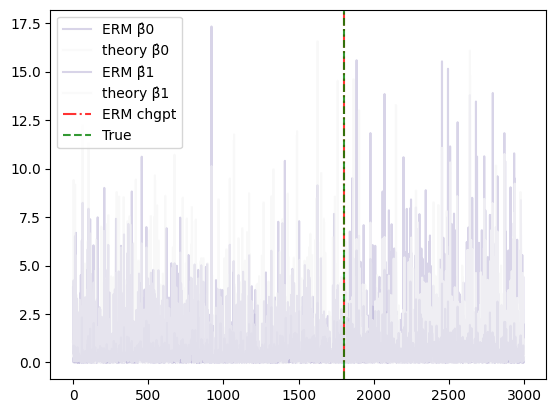

100%|██████████| 6/6 [00:05<00:00,  1.09it/s]


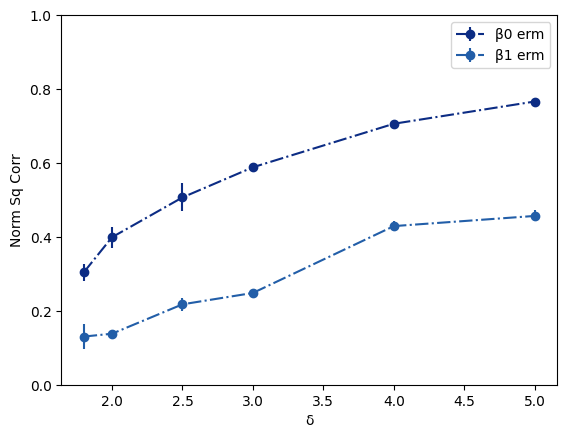

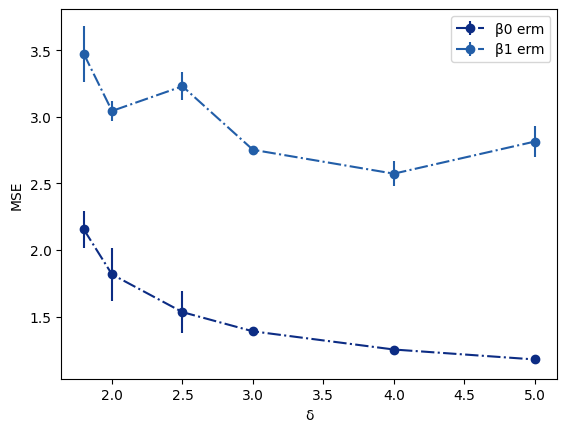

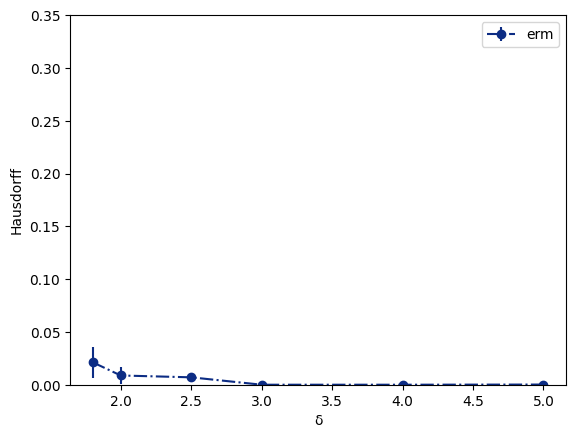

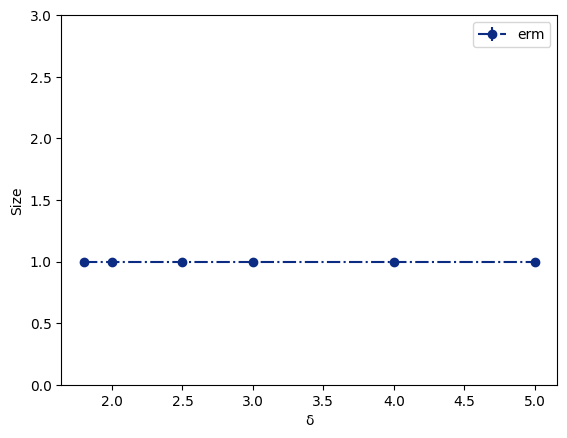

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import WERM.marginals
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

p = 600
L = 2 # num signals. L-1 changepoints
noise_std = 1

δ_list = [1.8, 2.0, 2.5, 3.0, 4.0, 5.0]
# δ_list = [6.0, 7.0, 8.0, 9.0, 10.0]

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
# M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 2

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.6])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
erm_haus_arr = np.zeros((len(δ_list), num_trials))
erm_size_arr = np.zeros((len(δ_list), num_trials))
erm_runtime = np.zeros((len(δ_list), num_trials))
theory_corr_arr = np.zeros((len(δ_list), num_trials, L))
theory_MSE_arr= np.zeros((len(δ_list), num_trials, L))
theory_haus_arr = np.zeros((len(δ_list), num_trials))
theory_size_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # --- Compute weights as marginals of prior --- #
    Δ = lambda n: 1
    π = np.zeros((L, n)) # Lxn matrix
    print("Computing marginals of prior...")
    for ℓ__ in range(1, L+1):
        for i__ in range(1, n+1):
            π[ℓ__-1, i__-1] = WERM.marginals.marginal_prior_approx_with_endpoints(
                l=ℓ__, i=i__, n=n, L=L, Delta=Δ(n), L_is_upper_bound=False
            )
    # Normalize π so that it sums to 1 for each signal (for stability of optimization)
    π = π / np.sum(π, axis=1, keepdims=True) # Lxn matrix

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    # B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    key = jax.random.PRNGKey(0)

    for trial_num in tqdm(range(num_trials)):
        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        # ε = jax.random.t(key, 5, shape=(n, ))
        # ε = np.random.standard_t(5, size=(n, ))
        # ε = np.random.randn(n) * noise_std
        ε = np.random.uniform(0, 1, size=(n, ))

        Θ = X @ B̃
        # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
        y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        # y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        B̂_theory = np.zeros((p, L))

        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_linear_model) # Compute the fixed point solution to general problem
        # print("Computing fixed point solution...")
        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, π, ε, n, model.q_logistic_model) # Compute the fixed point solution to general problem
        # print("b = ", b)
        # print("ν̃ = ", ν̃)
        # print("κ̃ = ", κ̃)
        # κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))  # stabilize

        # Time the execution of the ERM and save it
        start_time_erm = time.time()
        for ℓ_ in range(L): 

            # Compute metrics for the theory
            # G_sample = np.random.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
            # β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]
            # B̂_theory[:, ℓ_] = β̂_theory
            # theory_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_])) # For ERM compute once
            # theory_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

            # Compute the empirical risk minimization (ERM) solution and metrics
            print("Regressing on signal ", ℓ_)
            sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

            # Compute weighted ERM estimator
            empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
            res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
            print("ERM opt result: ", res) 
            β̂ = res.x
            B̂[:, ℓ_] = β̂
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂, B̃[:, ℓ_])) # For ERM compute once
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))


        ### --- Compute Change point estimates --- ###

        ## Compute Chgpt estimate for ERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), M(X @ B̂_theory[:, ℓ], y), c = PAL[-2 - ℓ_], alpha = 0.5, label="theory β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
        # opt_chgpt_loc_erm = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
        # opt_chgpt_loc_theory, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂_theory, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
        # opt_chgpt_loc_theory = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        # print("Theory chpt estimate: ", opt_chgpt_loc_theory)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        erm_runtime[i, trial_num] = time.time() - start_time_erm

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        # [plt.axvline(x=loc, color='y', linestyle='dotted', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_theory]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        erm_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        # theory_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_theory, true_chgpt_locations(n)))
        erm_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
        theory_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
    
        plt.legend()
        plt.show()

PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    # plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    # plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# Below is old code before new implementation

# Linear Model with Huber Loss 

  0%|          | 0/5 [00:00<?, ?it/s]

δ =  6.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4702 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-7.303e-11 -1.699e-13  9.922e-12  1.274e-14  2.290e-12
                1.935e-14 -4.940e-11  2.110e-12  2.110e-12  5.196e-14]
           x: [ 2.674e+00  2.553e+00  1.054e+00  4.949e-01  2.225e-01
                7.290e-01  1.473e+00  7.591e-01  1.222e+00]
        cost: 3.9433654234222285e-21
         jac: [[ 4.666e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  4.918e-02 ... -1.384e-02 -2.216e-02]
               ...
               [-3.372e-01 -3.532e-01 ...  1.271e+00 -1.327e-02]
               [ 0.000e+00 -1.188e+00 ...  1.141e+00  1.851e+00]]
        grad: [ 5.348e-11 -1.560e-12 -1.926e-12 -1.390e-13  3.364e-12
                1.015e-13 -1.036e-10  5.426e-12  4.464e-14]
  optimality: 1.4301527725080255e-10
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 10
        njev: 10 success =  True , message =  `gtol` termination conditio

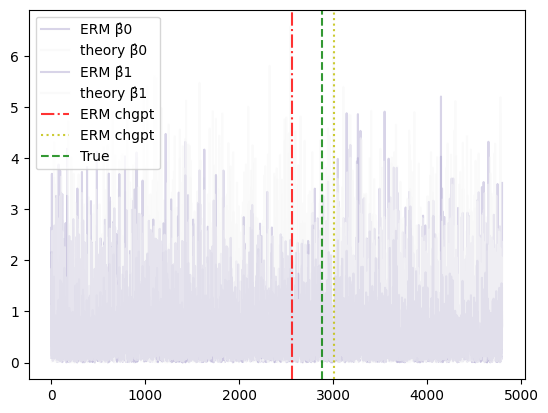

 50%|█████     | 1/2 [00:31<00:31, 31.30s/it]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-3.504e-11 -9.899e-15  5.363e-12  3.464e-16  1.267e-12
                7.203e-16 -1.105e-11  5.901e-13  5.899e-13  1.048e-14]
           x: [ 2.655e+00  2.557e+00  1.028e+00  4.952e-01  2.262e-01
                7.290e-01  1.464e+00  7.570e-01  1.222e+00]
        cost: 6.90486830502233e-22
         jac: [[ 4.701e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  4.909e-02 ... -1.379e-02 -2.230e-02]
               ...
               [-3.368e-01 -3.497e-01 ...  1.265e+00 -1.252e-02]
               [ 0.000e+00 -1.185e+00 ...  1.137e+00  1.856e+00]]
        grad: [ 1.094e-11 -4.256e-13 -3.337e-13 -3.457e-14  7.131e-13
                2.802e-14 -2.241e-11  1.504e-12  4.923e-15]
  optimality: 2.9036900585847432e-11
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 10
        njev: 10 success =  True , message =  `gtol` termination condition 

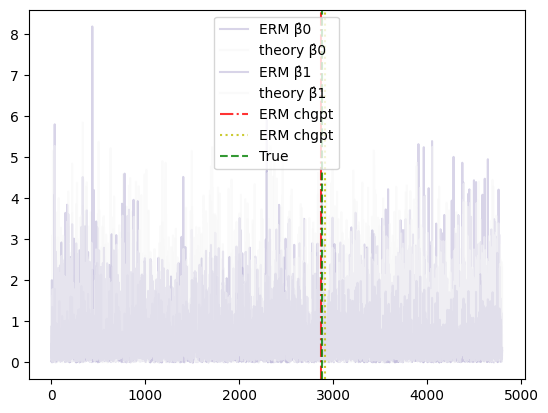

 20%|██        | 1/5 [00:59<03:56, 59.21s/it]

δ =  7.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/5486 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.030e-12 -7.538e-15  1.857e-13  6.840e-16  4.108e-14
                1.094e-15 -9.353e-14 -5.014e-15 -4.896e-15  2.287e-16]
           x: [ 2.046e+00  1.977e+00  9.628e-01  4.375e-01  2.093e-01
                7.130e-01  1.262e+00  6.488e-01  1.060e+00]
        cost: 5.534665582748403e-25
         jac: [[ 5.506e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  5.724e-02 ... -1.255e-02 -2.041e-02]
               ...
               [-3.360e-01 -3.475e-01 ...  1.121e+00 -9.649e-03]
               [ 0.000e+00 -1.212e+00 ...  1.033e+00  1.681e+00]]
        grad: [ 5.882e-14  2.734e-15 -2.640e-15  2.291e-16  5.062e-15
               -1.799e-16 -1.627e-13 -1.076e-14  6.636e-16]
  optimality: 1.6269534679355474e-13
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 10
        njev: 10 success =  True , message =  `gtol` termination condition

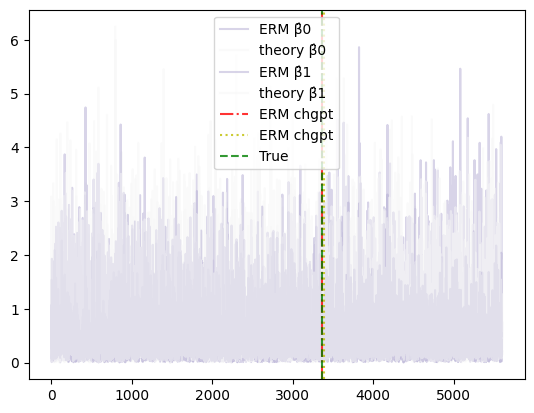

 50%|█████     | 1/2 [00:32<00:32, 32.54s/it]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.010e-12 -2.293e-14  1.825e-13  1.953e-15  3.975e-14
                3.044e-15 -9.435e-14 -4.733e-15 -4.733e-15 -9.111e-16]
           x: [ 2.048e+00  1.965e+00  9.713e-01  4.342e-01  2.084e-01
                6.853e-01  1.262e+00  6.497e-01  1.063e+00]
        cost: 5.321108448345514e-25
         jac: [[ 5.499e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  5.767e-02 ... -1.277e-02 -2.066e-02]
               ...
               [-3.361e-01 -3.504e-01 ...  1.121e+00 -9.824e-03]
               [ 0.000e+00 -1.225e+00 ...  1.035e+00  1.681e+00]]
        grad: [ 6.067e-14  3.108e-15 -2.660e-15  2.875e-16  4.926e-15
               -2.098e-16 -1.646e-13 -1.121e-14 -8.834e-16]
  optimality: 1.645824997336955e-13
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 10
        njev: 10 success =  True , message =  `gtol` termination condition 

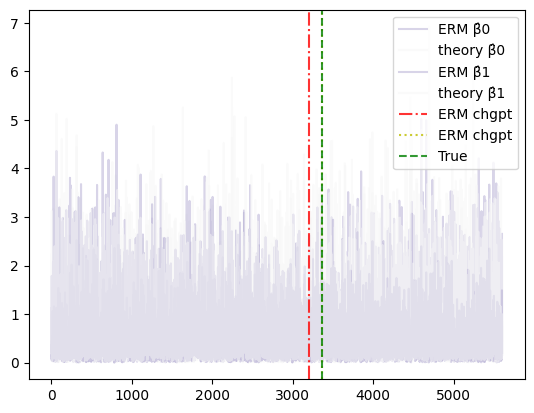

 40%|████      | 2/5 [02:02<03:05, 61.86s/it]

δ =  8.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/6270 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.607e-09 -1.102e-11  2.602e-10  2.959e-13  5.468e-11
                5.690e-13 -4.492e-10  2.459e-12  2.459e-12 -8.420e-12]
           x: [ 1.679e+00  1.617e+00  9.345e-01  4.164e-01  1.964e-01
                6.662e-01  1.129e+00  5.761e-01  9.502e-01]
        cost: 1.4281656688891761e-18
         jac: [[ 6.077e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  6.341e-02 ... -1.116e-02 -1.851e-02]
               ...
               [-3.337e-01 -3.464e-01 ...  1.020e+00 -6.832e-03]
               [ 0.000e+00 -1.229e+00 ...  9.466e-01  1.561e+00]]
        grad: [ 4.466e-10  7.949e-12 -7.691e-12  4.416e-13  2.099e-11
               -2.188e-13 -7.859e-10 -2.824e-12 -1.296e-11]
  optimality: 7.859134874786509e-10
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 9
        njev: 9 success =  True , message =  `gtol` termination condition i

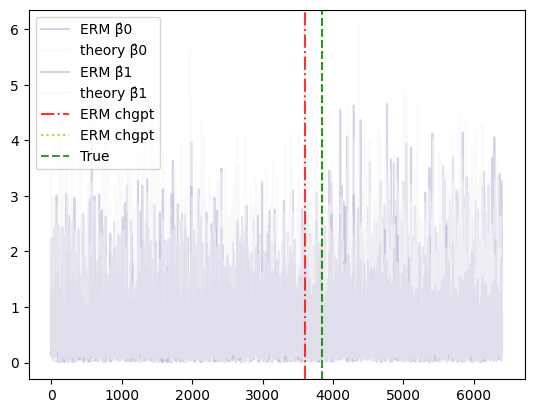

 50%|█████     | 1/2 [00:32<00:32, 32.60s/it]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-8.038e-10 -6.955e-12  1.338e-10  1.549e-13  2.811e-11
                3.047e-13 -2.163e-10  3.799e-12  3.799e-12 -5.872e-12]
           x: [ 1.693e+00  1.622e+00  9.660e-01  4.305e-01  2.026e-01
                6.704e-01  1.129e+00  5.775e-01  9.504e-01]
        cost: 3.5585422567219207e-19
         jac: [[ 6.014e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  6.317e-02 ... -1.116e-02 -1.845e-02]
               ...
               [-3.317e-01 -3.463e-01 ...  1.022e+00 -6.649e-03]
               [ 0.000e+00 -1.227e+00 ...  9.507e-01  1.561e+00]]
        grad: [ 2.098e-10  4.136e-12 -3.524e-12  2.194e-13  1.001e-11
               -9.578e-14 -3.758e-10  2.263e-12 -9.083e-12]
  optimality: 3.7580704495766457e-10
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 9
        njev: 9 success =  True , message =  `gtol` termination condition 

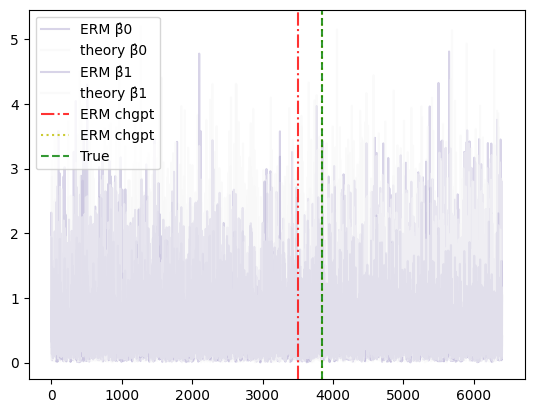

 60%|██████    | 3/5 [03:08<02:07, 63.52s/it]

δ =  9.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/7054 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-3.793e-13 -4.318e-16  5.364e-14 -1.071e-17  1.193e-14
               -3.864e-18 -1.524e-13  6.454e-15  6.454e-15  5.177e-16]
           x: [ 1.443e+00  1.381e+00  9.509e-01  4.085e-01  2.085e-01
                6.940e-01  1.035e+00  5.249e-01  8.719e-01]
        cost: 8.509353946974732e-26
         jac: [[ 6.437e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  6.760e-02 ... -1.001e-02 -1.647e-02]
               ...
               [-3.304e-01 -3.451e-01 ...  9.476e-01 -4.254e-03]
               [ 0.000e+00 -1.240e+00 ...  8.823e-01  1.469e+00]]
        grad: [ 1.575e-13 -5.126e-15 -1.348e-15 -2.659e-16  5.954e-15
                2.041e-16 -2.500e-13  1.269e-14  7.128e-16]
  optimality: 2.4998986209391283e-13
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 9
        njev: 9 success =  True , message =  `gtol` termination condition i

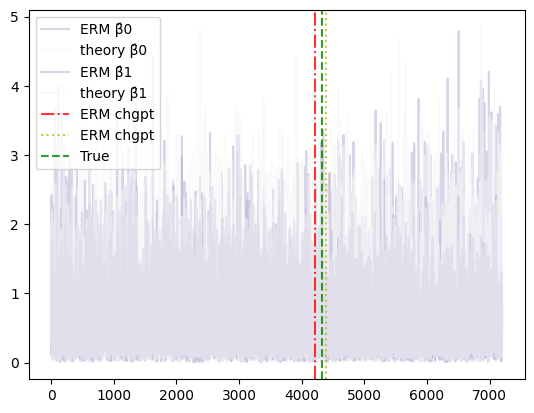

 50%|█████     | 1/2 [00:35<00:35, 35.36s/it]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-4.701e-13 -7.648e-17  6.943e-14  1.785e-17  1.401e-14
               -6.011e-18 -1.690e-13  7.291e-15  7.527e-15  6.657e-16]
           x: [ 1.435e+00  1.370e+00  9.334e-01  4.011e-01  1.866e-01
                6.621e-01  1.031e+00  5.253e-01  8.703e-01]
        cost: 1.2733735852073116e-25
         jac: [[ 6.480e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  6.823e-02 ... -1.017e-02 -1.665e-02]
               ...
               [-3.316e-01 -3.471e-01 ...  9.442e-01 -5.281e-03]
               [ 0.000e+00 -1.248e+00 ...  8.838e-01  1.464e+00]]
        grad: [ 1.709e-13 -5.979e-15 -1.327e-15 -3.115e-16  6.083e-15
                2.269e-16 -2.749e-13  1.458e-14  8.973e-16]
  optimality: 2.74892881990503e-13
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 9
        njev: 9 success =  True , message =  `gtol` termination condition is

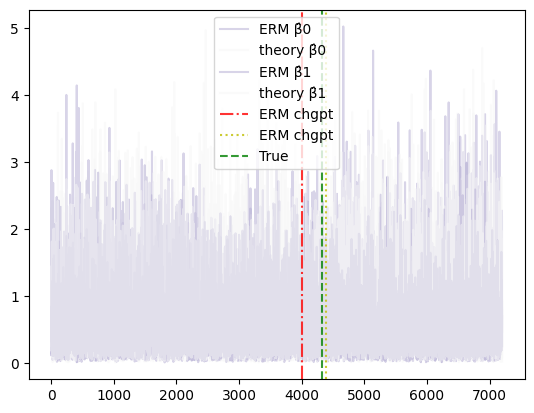

 80%|████████  | 4/5 [04:18<01:06, 66.30s/it]

δ =  10.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/7838 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.482e-09 -3.431e-14  3.057e-10  7.378e-15  6.312e-11
                1.188e-14 -1.012e-10 -1.633e-11 -1.633e-11  9.050e-13]
           x: [ 1.235e+00  1.191e+00  8.741e-01  3.959e-01  1.808e-01
                6.535e-01  9.529e-01  4.802e-01  8.076e-01]
        cost: 1.1516000492217133e-18
         jac: [[ 6.918e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  7.202e-02 ... -9.017e-03 -1.510e-02]
               ...
               [-3.304e-01 -3.423e-01 ...  8.819e-01 -4.028e-03]
               [ 0.000e+00 -1.253e+00 ...  8.236e-01  1.385e+00]]
        grad: [ 3.328e-11  1.004e-11 -8.097e-13  4.806e-13  3.999e-12
               -3.954e-13 -1.488e-10 -2.805e-11  1.385e-12]
  optimality: 1.4876235479011438e-10
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 8
        njev: 8 success =  True , message =  `gtol` termination condition 

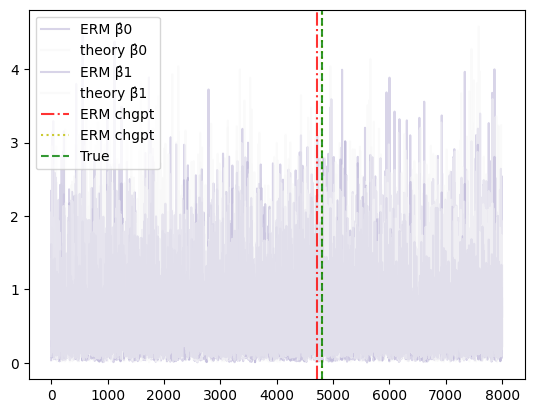

 50%|█████     | 1/2 [00:37<00:37, 37.72s/it]

Optimization Results: all =       message: `gtol` termination condition is satisfied.
     success: True
      status: 1
         fun: [-1.445e-09 -2.851e-14  3.141e-10  6.832e-15  6.417e-11
                1.060e-14 -8.916e-11 -1.602e-11 -1.602e-11  8.367e-13]
           x: [ 1.251e+00  1.197e+00  9.186e-01  4.200e-01  1.880e-01
                6.643e-01  9.577e-01  4.819e-01  8.098e-01]
        cost: 1.1001842454944965e-18
         jac: [[ 6.821e-02  0.000e+00 ...  0.000e+00  0.000e+00]
               [ 0.000e+00  7.158e-02 ... -8.920e-03 -1.501e-02]
               ...
               [-3.288e-01 -3.432e-01 ...  8.856e-01 -3.379e-03]
               [ 0.000e+00 -1.252e+00 ...  8.249e-01  1.390e+00]]
        grad: [ 2.167e-11  9.947e-12 -8.277e-13  4.833e-13  3.611e-12
               -3.898e-13 -1.305e-10 -2.769e-11  1.272e-12]
  optimality: 1.3045033339244887e-10
 active_mask: [0 0 0 0 0 0 0 0 0]
        nfev: 8
        njev: 8 success =  True , message =  `gtol` termination condition 

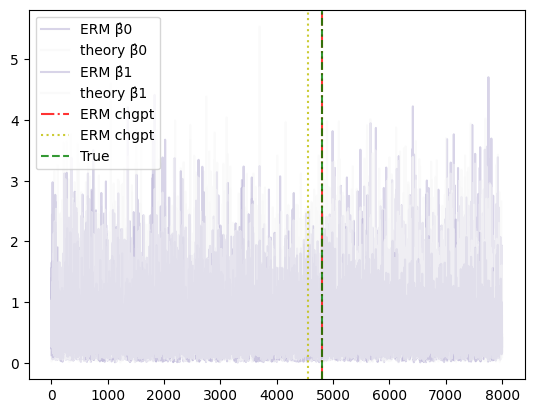

100%|██████████| 5/5 [05:33<00:00, 66.66s/it]


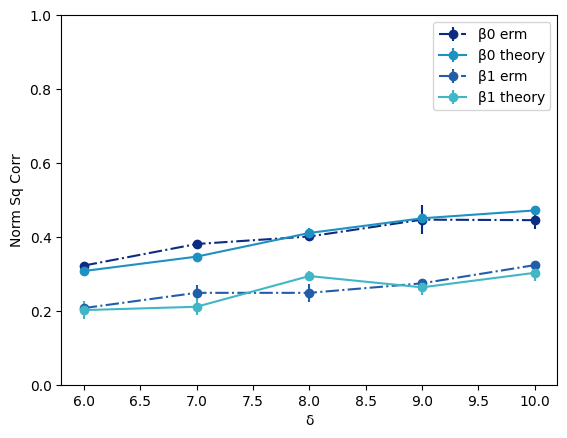

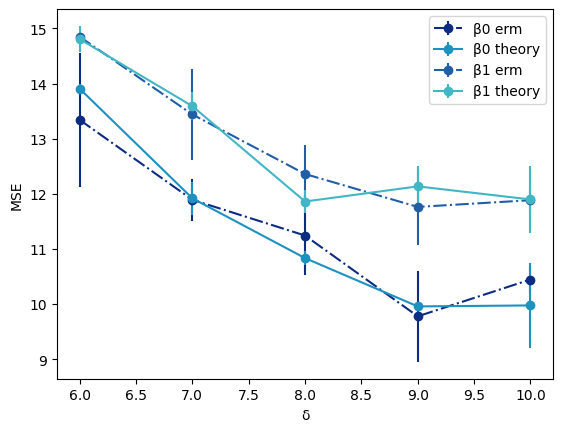

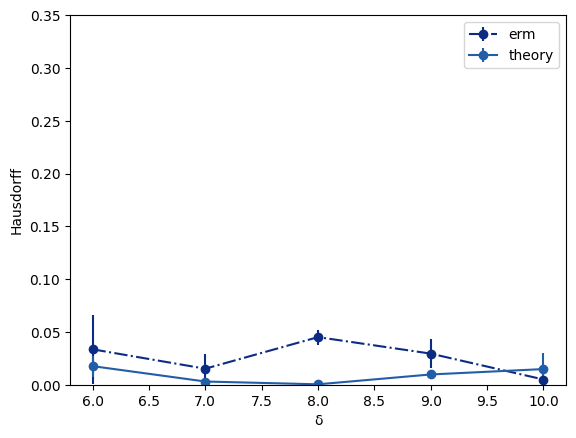

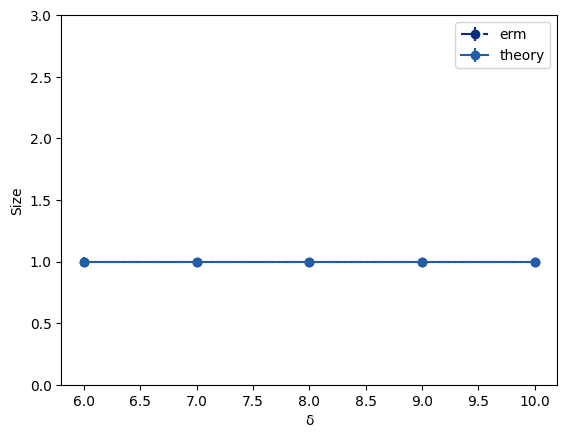

In [1]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

p = 800
L = 2 # num signals. L-1 changepoints
noise_std = 1

# δ_list = [1.8, 2.0, 2.5, 3.0, 4.0, 5.0]
δ_list = [6.0, 7.0, 8.0, 9.0, 10.0]

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# Logistic loss
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
num_trials = 2

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.6])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
erm_haus_arr = np.zeros((len(δ_list), num_trials))
erm_size_arr = np.zeros((len(δ_list), num_trials))
erm_runtime = np.zeros((len(δ_list), num_trials))
theory_corr_arr = np.zeros((len(δ_list), num_trials, L))
theory_MSE_arr= np.zeros((len(δ_list), num_trials, L))
theory_haus_arr = np.zeros((len(δ_list), num_trials))
theory_size_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 1.0
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    # B̃_cov = κ**2 * δ * np.array([[1.0, 0.0], [0.0, 1.0]]) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    key = jax.random.PRNGKey(0)

    for trial_num in tqdm(range(num_trials)):
        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        # ε = jax.random.t(key, 5, shape=(n, ))
        # ε = np.random.standard_t(5, size=(n, ))
        # ε = np.random.randn(n) * noise_std
        ε = np.random.uniform(0, 1, size=(n, ))

        Θ = X @ B̃
        # y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()
        # y = jax.vmap(model.q_linear_model, in_axes=(0, 0, 0))(Θ, C_true, ε)
        y = jax.vmap(model.q_logistic_model, in_axes = (0, 0, 0))(Θ, C_true, ε)

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        B̂_theory = np.zeros((p, L))

        # b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, ϕ, ε, n, model.q_linear_model) # Compute the fixed point solution to general problem
        b, ν̃, κ̃ = fp.general_fp(M, ρ, δ, fractional_chgpt_locations, ϕ, ε, n, model.q_logistic_model) # Compute the fixed point solution to general problem
        print("b = ", b)
        print("ν̃ = ", ν̃)
        print("κ̃ = ", κ̃)
        κ̃_sqrt = jnp.linalg.cholesky(κ̃ + 1e-12 * jnp.eye(L))  # stabilize

        # Time the execution of the ERM and save it
        start_time_erm = time.time()
        for ℓ_ in range(L): 

            # Compute metrics for the theory
            G_sample = np.random.multivariate_normal(np.zeros((L, )), np.eye(L), size=(p,)) @ κ̃_sqrt.T
            β̂_theory = B̃ @ ν̃[:, ℓ_] + δ**(1/2) * G_sample[:, ℓ_]
            B̂_theory[:, ℓ_] = β̂_theory
            theory_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_theory, B̃[:, ℓ_])) # For ERM compute once
            theory_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_theory.flatten(), B̃[:, ℓ_]))

            # Compute the empirical risk minimization (ERM) solution and metrics
            print("Regressing on signal ", ℓ_)
            sample_weight = ϕ[ℓ_, :] / np.sum(ϕ[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

            # Compute weighted ERM estimator
            empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
            res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
            print("ERM opt result: ", res) 
            β̂ = res.x
            B̂[:, ℓ_] = β̂
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂, B̃[:, ℓ_])) # For ERM compute once
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))


        ### --- Compute Change point estimates --- ###

        ## Compute Chgpt estimate for ERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), M(X @ B̂_theory[:, ℓ], y), c = PAL[-2 - ℓ_], alpha = 0.5, label="theory β̂" + str(ℓ))

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.logistic_reg_opt_chgpt_gof(X @ B̂, y, η_arr, p_η_arr)
        # Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
        opt_chgpt_loc_theory = WERM.gof.logistic_reg_opt_chgpt_gof(X @ B̂_theory, y, η_arr, p_η_arr)
        print("WERM chpt estimate: ", opt_chgpt_loc_erm)
        print("Theory chpt estimate: ", opt_chgpt_loc_theory)
        print("Done optimizing gof erm.")
        
        # Save the runtime
        erm_runtime[i, trial_num] = time.time() - start_time_erm

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=loc, color='y', linestyle='dotted', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_theory]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]

        erm_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        theory_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_theory, true_chgpt_locations(n)))
        erm_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
        theory_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))
    
        plt.legend()
        plt.show()

PAL = ['#0c2c84','#225ea8','#1d91c0','#41b6c4','#7fcdbb','#c7e9b4','#edf8b1','#ffffd9']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-.", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(theory_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(theory_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " theory", marker="o", ls="-", c=PAL[ℓ_ + L], alpha = 1.0)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_haus_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_haus_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(erm_size_arr, axis = 1), yerr = np.std(erm_haus_arr, axis = 1), label="erm", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, np.mean(theory_size_arr, axis = 1), yerr = np.std(theory_haus_arr, axis = 1), label="theory", marker="o", ls="-", c=PAL[1], alpha = 1.0)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Runtime plots
# δ_arr = np.array([δ_list for _ in range(num_trials)])
# plt.errorbar(δ_list, np.mean(ERM_runtime, axis = 1), yerr = np.std(ERM_runtime, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[0], alpha = 1.0)
# plt.xlabel("δ")
# plt.ylabel("Runtime")
# plt.legend()
# plt.show()

# Linear Model with change points: estimate ρ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 2 # num signals. L-1 changepoints

δ_list = [2.0]
noise_std = 0.2
M = lambda t: jnp.power(t, 2)

# chgpt_locations = np.array([0.3, 0.7])
fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])
# chgpt_locations = np.array([])

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Gaussian Signal Prior
    κ = 2.3
    B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = ρ
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    y = lin_reg(Θ, C_true, noise_std).astype(np.float64).flatten()

    Δρ_arr = []
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(10)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        for ℓ_ in range(L):

            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # μ̃_arr, σ̃, μ_arr, σ = fp_linear_model_unif_prior(M, ρ, L, fractional_chgpt_locations, δ, n, noise_std)
            # π = ϕ[ℓ_, :]
            π = np.ones(n) # Set to a trivial prior to test
            ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
            μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
            ν[:, ℓ_] = μ̃_arr
            κ_mat[ℓ_, ℓ_] = (σ̃)**2 / δ
            # print("σ̃ = ", σ̃)
            β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

            # print("Regressing on signal ", ℓ_)
            sample_weight = π
            sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
            sk_lin_reg.fit(X, y, sample_weight = sample_weight)
            β̂ = sk_lin_reg.coef_

            B̂[:, ℓ_] = β̂
            Θ̂_erm[:, ℓ_] = X @ β̂
            print("### --- Debiasing... --- ###")
            Θ_t_erm[:, ℓ_] = debias_M_est(X @ β̂, y, b, π, X @ β̂)
            # loss = lambda u, v: M(u - v)
            # β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
            # Θ_t_erm[:, ℓ_] = θ_t
            
            # erm_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂, B̃[:, ℓ_]))
            # amp_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            # comparison_corr_list[ℓ_].append(WERM.norm_sq_corr(β̂_amp.flatten(), β̂.flatten()))
            # comparison_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), β̂.flatten()))
            # erm_MSE_list[ℓ_].append(WERM.MSE(β̂.flatten(), B̃[:, ℓ_]))
            # amp_MSE_list[ℓ_].append(WERM.MSE(β̂_amp.flatten(), B̃[:, ℓ_]))
            # G = np.random.randn(p)
            # theory_MSE_list[ℓ_].append(WERM.MSE(σ̃ * G, np.zeros(p)))

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν.T @ ρ @ ν + κ_mat
        assert np.all(np.linalg.eigvals(rhs) > 0)

        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
for ℓ_ in range(L):
    # Sqcorr plots
    plt.errorbar(δ_list, erm_corr_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_corr_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    plt.ylim((0, 1))
    plt.xlabel("δ")
    plt.ylabel("Norm Sq Corr")
    plt.legend()
    plt.show()

    # MSE plots
    # plt.errorbar(δ_list, comparison_MSE_list[ℓ_], label="β" + str(ℓ_) + " comp", marker="D", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, erm_MSE_list[ℓ_], label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, amp_MSE_list[ℓ_], label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
    # plt.errorbar(δ_list, theory_MSE_list[ℓ_], label="β" + str(ℓ_) + " theory", marker="x", ls="--", c=PAL[ℓ_], alpha = 1.0)
    plt.ylim((0, 2))
    plt.xlabel("δ")
    plt.ylabel("MSE")
    plt.legend()
    plt.show()

  0%|          | 0/1 [00:00<?, ?it/s]

δ =  2.0


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4898 [00:00<?, ?it/s]

True ρ:  [[5.30503167 0.06057046]
 [0.06057046 5.04832244]]


  0%|          | 0/10 [00:00<?, ?it/s]

# Linear Model without change points: estimate γ

In [ ]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
from WERM.model import *
from WERM.M_est_fixed_point_eqns import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
tqdm = partial(tqdm, position=0, leave=True)

p = 2000
L = 1 # num signals. L-1 changepoints

δ_list = [3.0 for _ in range(30)]
noise_std = 0.2
# M = lambda t: jnp.power(t, 2)

def huber_loss(t, epsilon = 1.35):
    residual = t
    condition = jnp.abs(residual) < epsilon
    squared_loss = jnp.square(residual)
    linear_loss = 2 * epsilon * (jnp.abs(residual) - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)
def M(t): return huber_loss(t)

erm_corr_list = [[] for ℓ_ in range(L)]
amp_corr_list = [[] for ℓ_ in range(L)]
erm_MSE_list = [[] for ℓ_ in range(L)]
amp_MSE_list = [[] for ℓ_ in range(L)]
theory_MSE_list = [[] for ℓ_ in range(L)]
comparison_corr_list = [[] for ℓ_ in range(L)]
comparison_MSE_list = [[] for ℓ_ in range(L)]

Δρ_trials_list = [[] for _ in δ_list]

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # Gaussian Signal Prior
    γ_squared = 2.3
    B̃_cov = γ_squared * δ * np.eye(L) # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    ρ̂ = np.eye(L)
    print("True ρ: ", ρ)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p))
    Θ = X @ B̃
    ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
    y = Θ.flatten() + ε.flatten()

    Δρ_arr = [np.linalg.norm(ρ - ρ̂)]
    print("Δρ: ", np.linalg.norm(ρ - ρ̂))
    # Ideas to fix: use the exact same noise vector, 
    for j in tqdm(range(4)): 
        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂ = np.zeros((p, L))
        Θ̂_erm = np.zeros((n, L))
        Θ_t_erm = np.zeros((n, L))
        ν = np.zeros((L, L))
        κ_mat = np.zeros((L, L))

        # π = ϕ[ℓ_, :]
        π = np.ones(n) # Set to a trivial prior to test
        ε = np.random.normal(0, noise_std, n) # Sample noise equivalent to that of the model
        fractional_chgpt_locations = np.array([])
        μ̃_arr, σ̃, μ_arr, σ, b = fp_lin_model(π, M, ρ̂, L, fractional_chgpt_locations, δ, n, ε)
        ν = μ̃_arr
        κ_mat = (σ̃)**2 / δ
        # print("σ̃ = ", σ̃)
        β̂_amp = B̃ @ μ̃_arr + σ̃ * np.random.normal(0, 1, p)

        # print("Regressing on signal ", ℓ_)
        # sample_weight = π
        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        # sk_lin_reg.fit(X, y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_

        # B̂[:, 0] = β̂
        # Θ̂_erm[:, 0] = X @ β̂
        print("### --- Debiasing... --- ###")
        # Run actual AMP
        loss = lambda u, v: M(u - v)
        β̂_amp_algo, θ̂_amp_algo, β_t, θ_t = WERM.amp(X, y, n, p, π, loss, max_iter = 20)
        Θ_t_erm[:, 0] = θ_t
        # Θ_t_erm[:, 0] = debias_M_est(X @ β̂, y, b, π, X @ β̂)

        # Solve for ρ
        # Check whether \nu^T \rho \nu + \kappa is positive definite and whether ν is invertible
        rhs = ν[0]**2 * ρ[0] + κ_mat
        # ρ̂ = np.linalg.inv(ν).T @ ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) @ np.linalg.inv(ν) # Attempt to solve for ρ using a solver instead?
        ρ̂ = ((1/n * Θ_t_erm.T @ Θ_t_erm) - κ_mat) * (ν[0])**(-2) # Attempt to solve for ρ using a solver instead?
        # ρ̂ = ρ
        lhs = (1/n * Θ_t_erm.T @ Θ_t_erm)
        print("lhs: ", lhs)
        print("rhs: ", rhs)
        print("lhs - rhs: ", lhs - rhs)
        print("ν: ", ν)
        print("κ_mat: ", κ_mat)

        print("ρ: ", ρ)
        print("ρ̂: ", ρ̂)
        print("Δρ: ", np.linalg.norm(ρ - ρ̂))
        print("ρ - ρ̂: ", ρ - ρ̂)
        Δρ_arr.append(np.linalg.norm(ρ - ρ̂))

    plt.plot(Δρ_arr)
    plt.title("Δρ")
    plt.show()

    Δρ_trials_list[i] = (ρ - ρ̂)[0][0]

  0%|          | 0/30 [00:00<?, ?it/s]

δ =  3.0
True ρ:  [[2.29926312]]
Δρ:  1.2992631192620925


  0%|          | 0/4 [00:00<?, ?it/s]

Optimization Results: x =  [0.13915975 0.25      ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 17, 'njev': 2, 'fjac': array([[-0.99974797, -0.02245001],
       [ 0.02245001, -0.99974797]]), 'r': array([ 0.67834903, -0.34038738,  2.71251879]), 'qtf': array([ 1.50002317e-10, -1.97273537e-10]), 'fvec': array([ 6.63358257e-14, -8.23785484e-14])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8965
Normalized MSE:  inf
c:  -1.1273399083057893
Normalized MSE:  0.0016907894014213808
c:  -1.2565751252482205
Normalized MSE:  6.540006530397817e-05
c:  -1.306726102282859
Normalized MSE:  2.9219610616825734e-05
c:  -1.3243446746573966
Normalized MSE:  1.106512042235334e-05
c:  -1.3303235869833683
Normalized MSE:  3.967475627603228e-06
c:  -1.3323285725124046
Normalized MSE:  1.427153942515998e-06
c:  -1.3329982447177355
Normalized MSE:  5.042366267769913e-07
c:  -1.333221618410936
Normalized MSE:  1.7466464331795598e-07
c:  -1.3332960929457154
Normalized MSE:  5.8297022484319916e-08
c:  -1.3333209196396467
Normalized MSE:  1.945813197342021e-08
c:  -1.3333291954097533
Normalized MSE:  6.260100145377167e-09
c:  -1.3333319540226187
Normalized MSE:  1.961548376423914e-09
c:  -1.333332873562779
Normalized MSE:  6.610417705828455e-10
c:  -1.3333331800764463
Normalized MSE:  2.0970115871136702e-10
c:  -1.3333332822477004
Normalized MSE:  6.669199798211594e-11
c:  -1.33333331630478

 25%|██▌       | 1/4 [01:18<03:55, 78.51s/it]

c:  -1.3333333327026462
Normalized MSE:  6.334287879950161e-13
lhs:  [[2.31524884]]
rhs:  [2.31862856]
lhs - rhs:  [[-0.00337972]]
ν:  [1.]
κ_mat:  0.01936543673002991
ρ:  [[2.29926312]]
ρ̂:  [[2.2958834]]
Δρ:  0.003379716920655529
ρ - ρ̂:  [[0.00337972]]
Optimization Results: x =  [0.1420479 0.25     ] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 18, 'njev': 1, 'fjac': array([[-0.99960252, -0.02819208],
       [ 0.02819208, -0.99960252]]), 'r': array([ 0.5936437 , -1.69293612,  3.01618855]), 'qtf': array([ 2.91613955e-09, -7.10659368e-10]), 'fvec': array([ 6.55919763e-13, -1.41220369e-13])}
μ̃_arr:  [1.]
### --- Debiasing... --- ###


  0%|          | 0/20 [00:00<?, ?it/s]

c:  -0.8993333333333333
Normalized MSE:  inf
c:  -1.1317281112530153
Normalized MSE:  0.001837767667786363
c:  -1.258178551717071
Normalized MSE:  6.489499300489029e-05
c:  -1.3073036103895601
Normalized MSE:  2.8373919240339e-05
c:  -1.3245423455302847
Normalized MSE:  1.054990065994643e-05
c:  -1.3303900669562407
Normalized MSE:  3.7810280989929356e-06
c:  -1.3323507986102618
Normalized MSE:  1.4109993676862359e-06
c:  -1.3330056607841476
Normalized MSE:  4.845417617096595e-07
c:  -1.333224091252456
Normalized MSE:  1.6100080078397194e-07


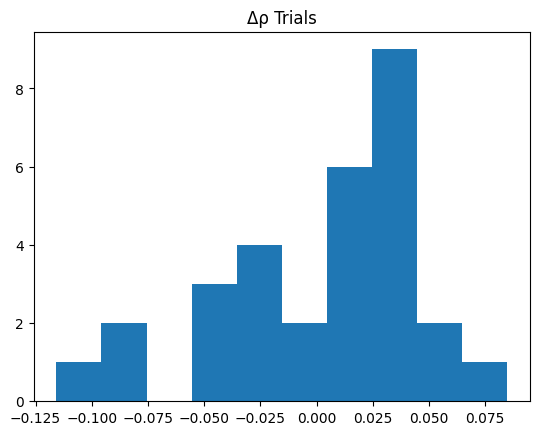

Mean:  0.0012376678106404526
Std:  0.04540794343623711


In [3]:
# Δρ_trials_list = np.array(Δρ_trials_list)
# Plot a histogram of Δρ_trials_list
plt.hist(Δρ_trials_list)
plt.title("Δρ Trials")
plt.show()

print("Mean: ", np.mean(Δρ_trials_list))
print("Std: ", np.std(Δρ_trials_list))